# Company Bankruptcy Prediction
## Notebook 2: Exploratory Data Analysis (EDA)

### Objective

To explore the cleaned dataset, understand the target distribution, analyze financial feature distributions and outliers, identify relationships with bankruptcy, and examine multicollinearity before model development.

**Input:** cleaned_Bankruptcy_data.csv

### Workflow

1. Setup and load data
2. Dataset overview
3. Target variable analysis
4. Summary statistics and skewness
5. Outlier analysis
6. Relationship between features and the target
7. Feature distributions by bankruptcy status
8. Multicollinearity analysis
9. Key findings
10. Next steps

### 1. Setup and Load Data

Import the required libraries and load the cleaned bankruptcy dataset. The original class distribution will be preserved throughout exploratory data analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
file_path = r"D:\Internship1\cleaned_Bankruptcy_data.csv"
data = pd.read_csv(file_path)

# Create a working copy
df = data.copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (6819, 95)


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,0.035490


## 2. Dataset Overview

This section provides an overview of the cleaned bankruptcy dataset, including its dimensions, column names, data types, and the number of numerical and categorical features. This helps us understand the structure of the dataset before performing exploratory data analysis.

In [2]:
# Display the number of rows and columns
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types of all columns
print("\nData Types:")
display(df.dtypes.to_frame(name="Data Type"))

# Count numerical and categorical columns
numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(exclude=np.number).columns

print("\nNumber of Numerical Columns:", len(numeric_columns))
print("Number of Categorical Columns:", len(categorical_columns))

Number of Rows: 6819
Number of Columns: 95

Column Names:
['Bankrupt?', 'ROA(C) before interest and depreciation before interest', 'ROA(A) before interest and % after tax', 'ROA(B) before interest and depreciation after tax', 'Operating Gross Margin', 'Realized Sales Gross Margin', 'Operating Profit Rate', 'Pre-tax net Interest Rate', 'After-tax net Interest Rate', 'Non-industry income and expenditure/revenue', 'Continuous interest rate (after tax)', 'Operating Expense Rate', 'Research and development expense rate', 'Cash flow rate', 'Interest-bearing debt interest rate', 'Tax rate (A)', 'Net Value Per Share (B)', 'Net Value Per Share (A)', 'Net Value Per Share (C)', 'Persistent EPS in the Last Four Seasons', 'Cash Flow Per Share', 'Revenue Per Share (Yuan ¥)', 'Operating Profit Per Share (Yuan ¥)', 'Per Share Net profit before tax (Yuan ¥)', 'Realized Sales Gross Profit Growth Rate', 'Operating Profit Growth Rate', 'After-tax Net Profit Growth Rate', 'Regular Net Profit Growth Rate', 

,Data Type
Bankrupt?,int64
ROA(C) before interest and depreciation before interest,float64
ROA(A) before interest and % after tax,float64
ROA(B) before interest and depreciation after tax,float64
Operating Gross Margin,float64
...,...
Net Income to Stockholder's Equity,float64
Liability to Equity,float64
Degree of Financial Leverage (DFL),float64
Interest Coverage Ratio (Interest expense to EBIT),float64



Number of Numerical Columns: 95
Number of Categorical Columns: 0


### 3. Target Variable Analysis

The target variable, Bankrupt?, indicates whether a company went bankrupt. In this section, we analyze the distribution of bankrupt and non-bankrupt companies using frequency counts, percentages, and a bar chart. This analysis helps us understand the class distribution and identify potential class imbalance.

In [3]:
# Count the number of companies in each target class
target_counts = df["Bankrupt?"].value_counts().sort_index()

# Calculate the percentage of each class
target_percentages = (
    df["Bankrupt?"].value_counts(normalize=True).sort_index() * 100
)

# Display the class distribution
target_summary = pd.DataFrame({
    "Company Count": target_counts,
    "Percentage (%)": target_percentages.round(2)
})

display(target_summary)

,Company Count,Percentage (%)
Bankrupt?,,
0,6599,96.77
1,220,3.23


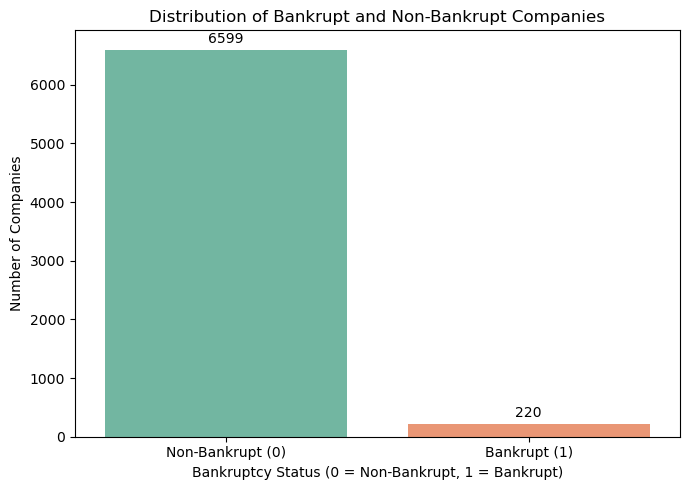

In [4]:
# Visualize the target class distribution
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Bankrupt?",
    hue="Bankrupt?",
    order=[0, 1],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Bankrupt and Non-Bankrupt Companies")
plt.xlabel("Bankruptcy Status (0 = Non-Bankrupt, 1 = Bankrupt)")
plt.ylabel("Number of Companies")
plt.xticks([0, 1], ["Non-Bankrupt (0)", "Bankrupt (1)"])

# Add count labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

### 4. Summary Statistics and Skewness Analysis

This section examines the statistical properties of the numerical features in the bankruptcy dataset. We use descriptive statistics to understand the central tendency, spread, and range of financial indicators. Skewness analysis helps identify features with asymmetric distributions, which may require further investigation before model development.

In [5]:
# Select numerical features, excluding the target variable
numeric_features = df.select_dtypes(include=np.number).columns.drop(
    "Bankrupt?"
)

# Generate descriptive statistics
summary_stats = df[numeric_features].describe().T

# Round values for readability
display(summary_stats.round(3))

,count,mean,std,min,25%,50%,75%,max
ROA(C) before interest and depreciation before interest,6819.0,0.505,0.061,0.0,0.477,0.503,0.536,1.0
ROA(A) before interest and % after tax,6819.0,0.559,0.066,0.0,0.536,0.560,0.589,1.0
ROA(B) before interest and depreciation after tax,6819.0,0.554,0.062,0.0,0.527,0.552,0.584,1.0
Operating Gross Margin,6819.0,0.608,0.017,0.0,0.600,0.606,0.614,1.0
Realized Sales Gross Margin,6819.0,0.608,0.017,0.0,0.600,0.606,0.614,1.0
...,...,...,...,...,...,...,...,...
Net Income to Stockholder's Equity,6819.0,0.840,0.015,0.0,0.840,0.841,0.842,1.0
Liability to Equity,6819.0,0.280,0.014,0.0,0.277,0.279,0.281,1.0
Degree of Financial Leverage (DFL),6819.0,0.028,0.016,0.0,0.027,0.027,0.027,1.0
Interest Coverage Ratio (Interest expense to EBIT),6819.0,0.565,0.013,0.0,0.565,0.565,0.566,1.0


In [6]:
# Calculate skewness for each numerical feature
skewness = df[numeric_features].skew()

# Create a sorted skewness summary
skewness_summary = (
    skewness
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .to_frame(name="Skewness")
)

display(skewness_summary.round(3))

,Skewness
Fixed Assets to Assets,82.577
Current Ratio,82.577
Total income/Total expense,82.332
Net Value Growth Rate,80.292
Contingent liabilities/Net worth,79.671
...,...
Quick Assets/Total Assets,0.337
ROA(C) before interest and depreciation before interest,-0.324
Cash Flow to Total Assets,-0.228
Working Capital to Total Assets,-0.192


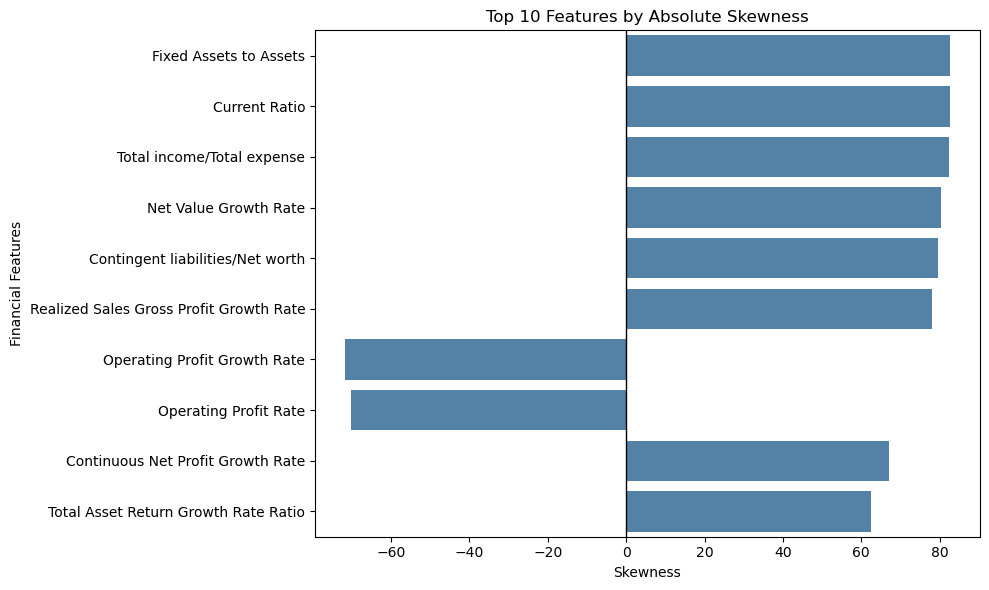

In [7]:
# Select the 10 features with the highest absolute skewness
top_skewed_features = skewness.abs().nlargest(10).index

plt.figure(figsize=(10, 6))

sns.barplot(
    x=skewness.loc[top_skewed_features].values,
    y=top_skewed_features,
    color="steelblue"
)

plt.title("Top 10 Features by Absolute Skewness")
plt.xlabel("Skewness")
plt.ylabel("Financial Features")
plt.axvline(x=0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

### 5. Outlier Analysis

Outlier analysis helps identify numerical observations that differ substantially from the majority of the data. In financial datasets, extreme values may represent unusual financial conditions or genuine business risks. We use the Interquartile Range (IQR) method and boxplots to identify potential outliers. These observations will be investigated rather than automatically removed.

In [8]:
# Calculate the number and percentage of potential outliers
# using the IQR method for each numerical feature

outlier_results = []

for column in numeric_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_percentage = (outlier_count / len(df)) * 100

    outlier_results.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage (%)": outlier_percentage
    })

outlier_summary = pd.DataFrame(outlier_results)

# Show features with the highest outlier percentages
outlier_summary = outlier_summary.sort_values(
    by="Outlier Percentage (%)",
    ascending=False
)

display(outlier_summary.head(15).round(3))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
91,Degree of Financial Leverage (DFL),2.700000e-02,2.700000e-02,1503,22.041
92,Interest Coverage Ratio (Interest expense to E...,5.640000e-01,5.670000e-01,1421,20.839
48,Fixed Assets Turnover Frequency,-5.000000e-03,9.000000e-03,1418,20.795
70,Current Asset Turnover Rate,-0.000000e+00,1.000000e-03,1399,20.516
28,Total Asset Growth Rate,1.065000e+09,1.118500e+10,1381,20.252
34,Interest Expense Ratio,6.300000e-01,6.320000e-01,1362,19.974
80,Cash Flow to Liability,4.460000e-01,4.750000e-01,1212,17.774
87,No-credit Interval,6.230000e-01,6.250000e-01,1139,16.703
8,Non-industry income and expenditure/revenue,3.030000e-01,3.040000e-01,1094,16.043
74,Cash Flow to Sales,6.720000e-01,6.720000e-01,1052,15.427


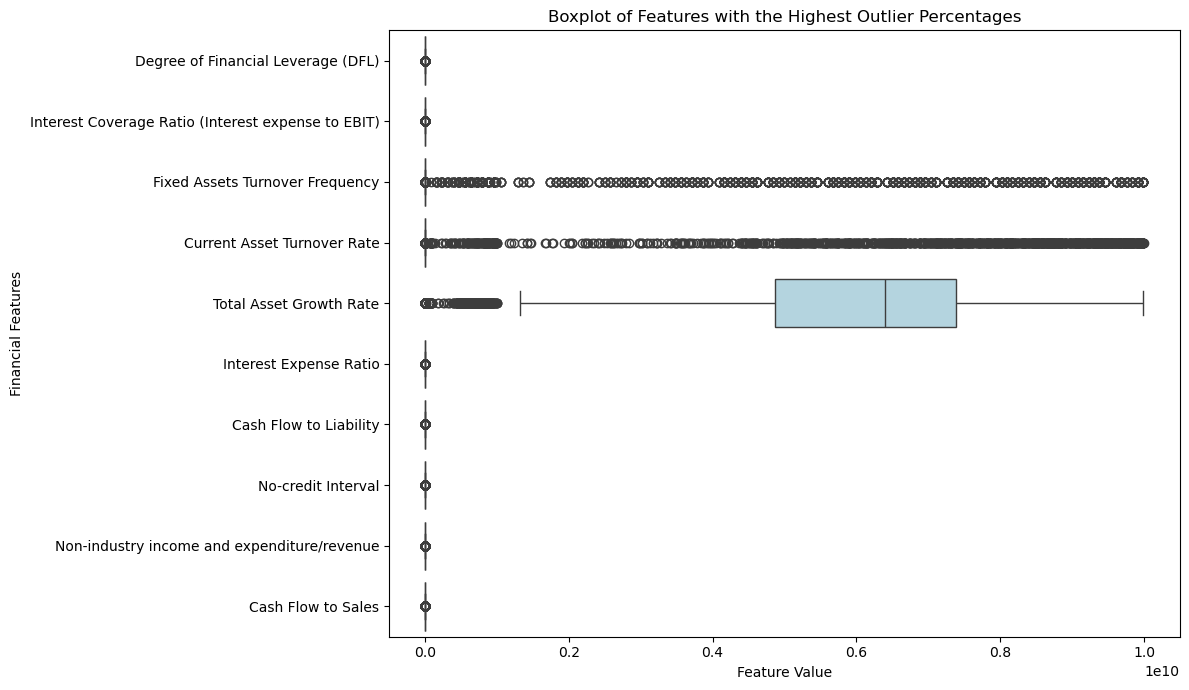

In [9]:
# Select the 10 features with the highest outlier percentages
top_outlier_features = outlier_summary.head(10)["Feature"].tolist()

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df[top_outlier_features],
    orient="h",
    color="lightblue"
)

plt.title("Boxplot of Features with the Highest Outlier Percentages")
plt.xlabel("Feature Value")
plt.ylabel("Financial Features")
plt.tight_layout()
plt.show()

## 6. Relationship Between Financial Features and Bankruptcy

This section investigates the relationship between selected financial indicators and bankruptcy status. We compare the average feature values of bankrupt and non-bankrupt companies to identify potential differences in their financial characteristics. These comparisons are exploratory and do not establish causation.

In [18]:
# Compare median values of numerical features by bankruptcy status
median_comparison = df.groupby("Bankrupt?")[numeric_features].median().T

# Rename columns
median_comparison.columns = [
    "Non-Bankrupt (0)",
    "Bankrupt (1)"
]

# Calculate median difference
median_comparison["Median Difference"] = (
    median_comparison["Bankrupt (1)"] -
    median_comparison["Non-Bankrupt (0)"]
)

display(median_comparison.round(4))

,Non-Bankrupt (0),Bankrupt (1),Median Difference
ROA(C) before interest and depreciation before interest,0.5043,0.4413,-0.0630
ROA(A) before interest and % after tax,0.5612,0.4902,-0.0710
ROA(B) before interest and depreciation after tax,0.5536,0.4886,-0.0650
Operating Gross Margin,0.6062,0.5988,-0.0074
Realized Sales Gross Margin,0.6062,0.5989,-0.0073
...,...,...,...
Net Income to Stockholder's Equity,0.8412,0.8367,-0.0045
Liability to Equity,0.2787,0.2859,0.0072
Degree of Financial Leverage (DFL),0.0268,0.0267,-0.0001
Interest Coverage Ratio (Interest expense to EBIT),0.5653,0.5647,-0.0005


In [11]:
# Select features using common financial indicator keywords
keywords = [
    "Debt ratio",
    "Net worth",
    "Return on",
    "Working capital",
    "Cash flow",
    "Current liability"
]

selected_features = [
    col for col in numeric_features
    if any(keyword.lower() in col.lower() for keyword in keywords)
]

# Limit the visualization to six features
selected_features = selected_features[:6]

print("Selected Features:", selected_features)

Selected Features: ['Cash flow rate', 'Cash Flow Per Share', 'Total debt/Total net worth', 'Debt ratio %', 'Net worth/Assets', 'Contingent liabilities/Net worth']


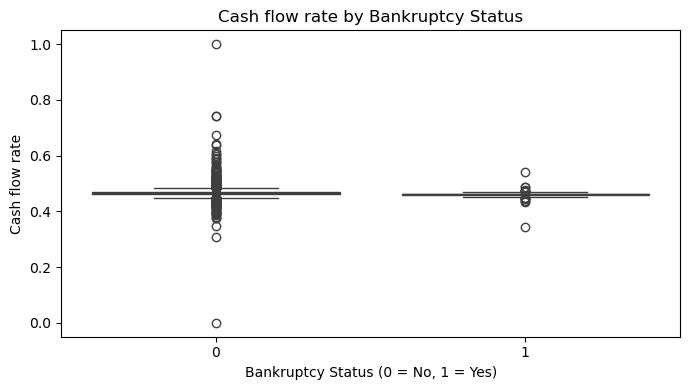

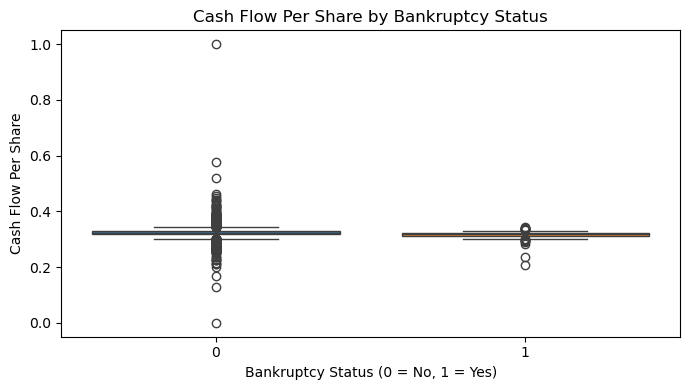

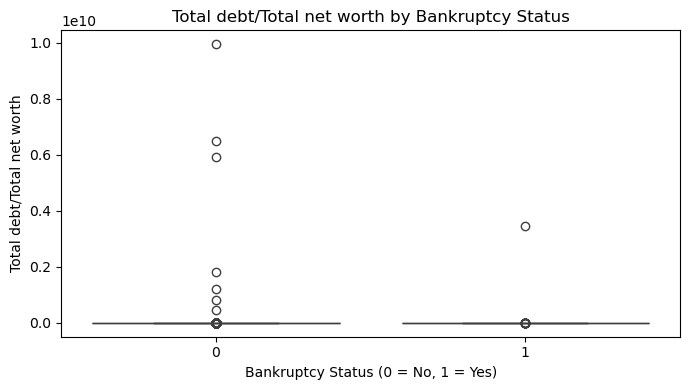

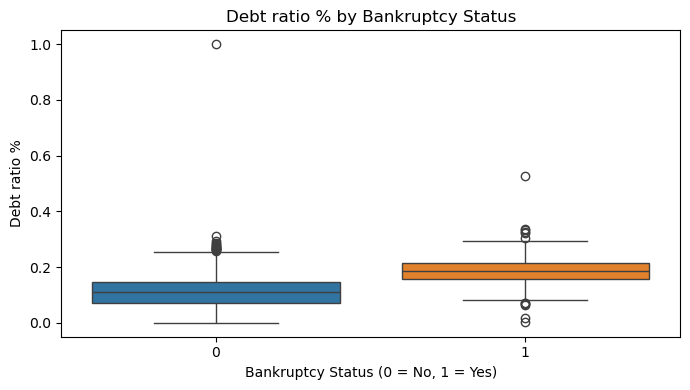

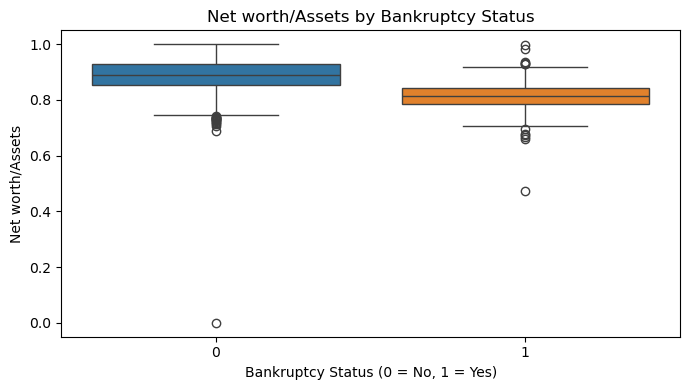

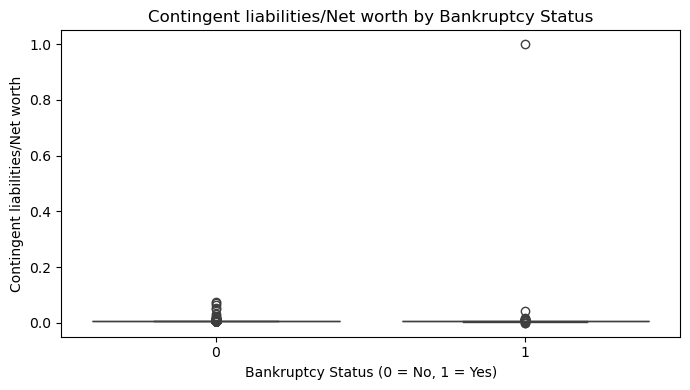

In [12]:
# Plot the selected features by bankruptcy status
if selected_features:
    for feature in selected_features:
        plt.figure(figsize=(7, 4))

        sns.boxplot(
            data=df,
            x="Bankrupt?",
            y=feature,
            hue="Bankrupt?",
            order=[0, 1],
            legend=False
        )

        plt.title(f"{feature} by Bankruptcy Status")
        plt.xlabel("Bankruptcy Status (0 = No, 1 = Yes)")
        plt.ylabel(feature)
        plt.tight_layout()
        plt.show()
else:
    print(
        "No matching features found. "
        "Review df.columns and select relevant financial indicators manually."
    )

### 7. Feature Distributions by Bankruptcy Status

This section compares the distributions of selected financial indicators for bankrupt and non-bankrupt companies. Histograms and density curves help reveal differences in the spread, concentration, and shape of financial variables across the two groups. These visual comparisons may help identify potentially useful features for subsequent model development.

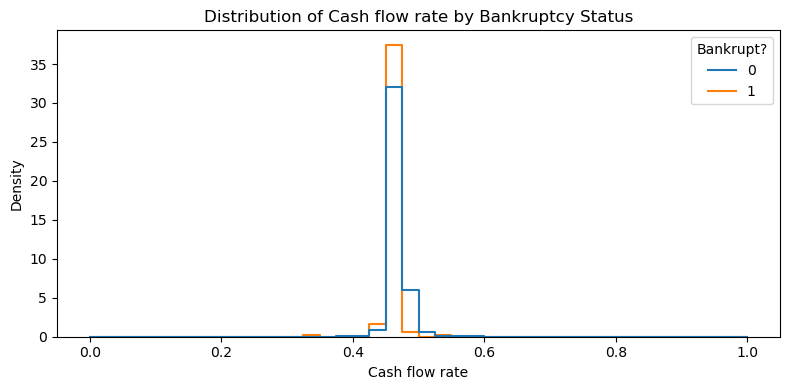

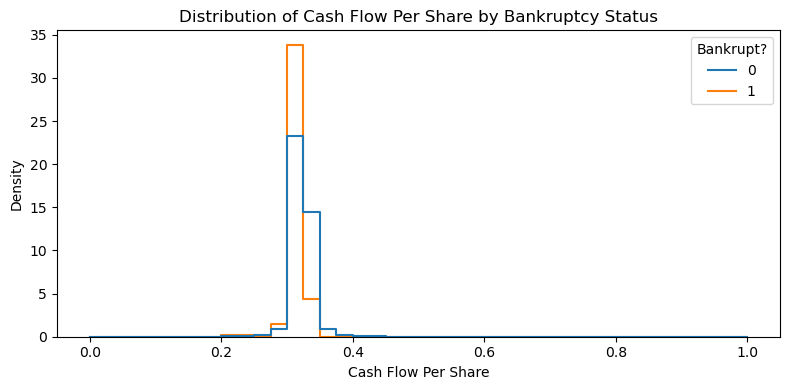

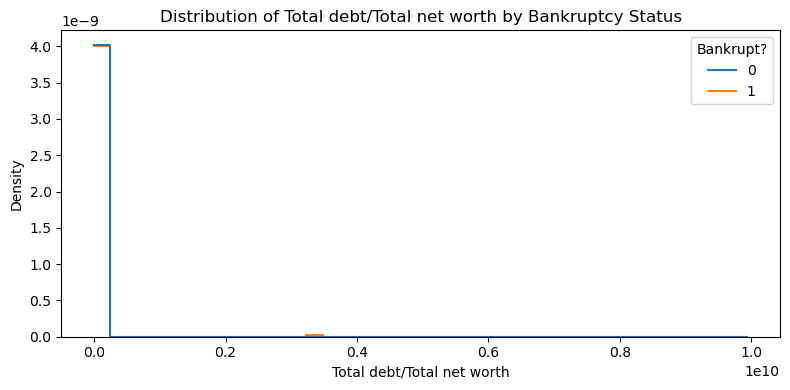

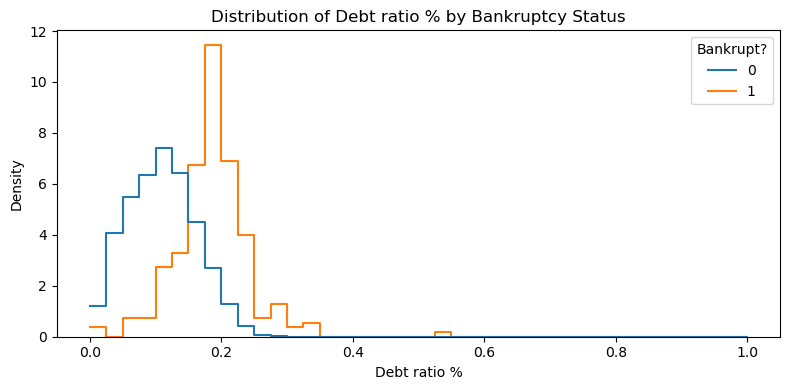

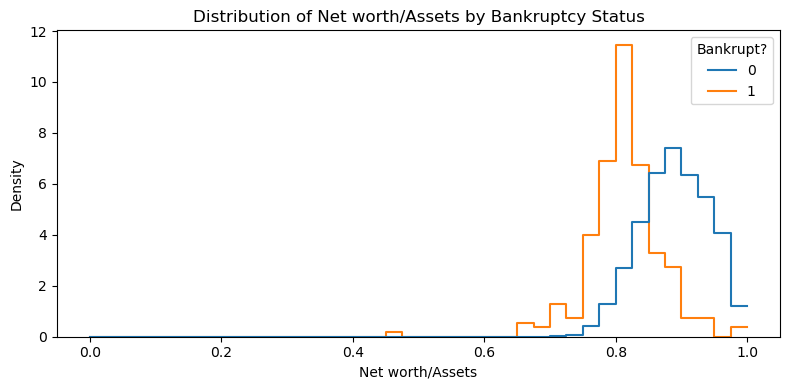

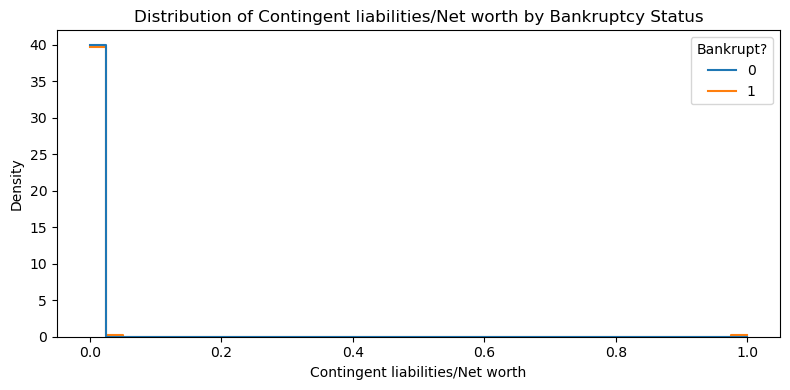

In [13]:
# Compare distributions of selected financial indicators
for feature in selected_features:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=feature,
        hue="Bankrupt?",
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        fill=False
    )

    plt.title(f"Distribution of {feature} by Bankruptcy Status")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()

### 8. Correlation and Multicollinearity Analysis

Correlation analysis helps identify the strength and direction of relationships between numerical financial indicators. A correlation matrix and heatmap are used to visualize these relationships. This analysis helps detect highly correlated features and potential multicollinearity before model development.

In [14]:
# Calculate correlation including the target variable
correlation_matrix = df.select_dtypes(include=np.number).corr()

# Extract correlation with the target variable
target_correlation = (
    correlation_matrix["Bankrupt?"]
    .drop("Bankrupt?")
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

# Display correlation values
display(
    target_correlation
    .to_frame(name="Correlation with Bankruptcy")
    .round(4)
)

,Correlation with Bankruptcy
Net Income to Total Assets,-0.3155
ROA(A) before interest and % after tax,-0.2829
ROA(B) before interest and depreciation after tax,-0.2731
ROA(C) before interest and depreciation before interest,-0.2608
Net worth/Assets,-0.2502
...,...
Inventory/Current Liability,0.0008
Long-term Liability to Current Assets,0.0008
Cash Flow to Sales,0.0005
Realized Sales Gross Profit Growth Rate,-0.0005


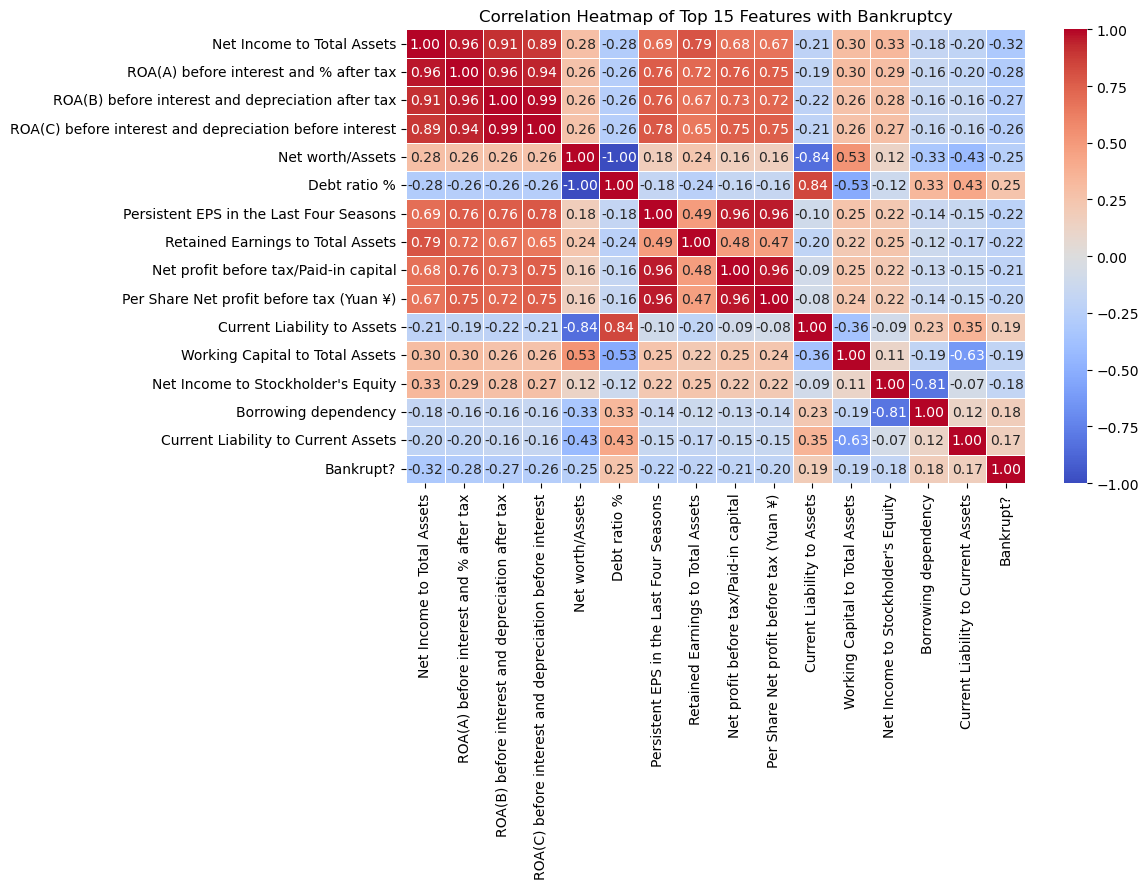

In [15]:
# Select the top 15 features correlated with the target
top_correlated_features = (
    target_correlation.abs()
    .nlargest(15)
    .index.tolist()
)

# Include the target variable
heatmap_features = top_correlated_features + ["Bankrupt?"]

# Calculate correlation for selected features
selected_correlation = df[heatmap_features].corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    selected_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Top 15 Features with Bankruptcy")
plt.tight_layout()
plt.show()

In [16]:
# Extract the upper triangle of the correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Identify feature pairs with absolute correlation above 0.90
high_correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_correlation_pairs = high_correlation_pairs[
    high_correlation_pairs["Correlation"].abs() > 0.90
]

# Sort by absolute correlation
high_correlation_pairs["Absolute Correlation"] = (
    high_correlation_pairs["Correlation"].abs()
)

high_correlation_pairs = high_correlation_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

display(high_correlation_pairs.round(4))

,Feature 1,Feature 2,Correlation,Absolute Correlation
4070,Current Liabilities/Equity,Current Liability to Equity,1.0000,1.0000
4012,Current Liabilities/Liability,Current Liability to Liability,1.0000,1.0000
2812,Debt ratio %,Net worth/Assets,-1.0000,1.0000
454,Operating Gross Margin,Gross Profit to Sales,1.0000,1.0000
1462,Net Value Per Share (A),Net Value Per Share (C),0.9998,0.9998
370,Operating Gross Margin,Realized Sales Gross Margin,0.9995,0.9995
543,Realized Sales Gross Margin,Gross Profit to Sales,0.9995,0.9995
1384,Net Value Per Share (B),Net Value Per Share (A),0.9993,0.9993
1385,Net Value Per Share (B),Net Value Per Share (C),0.9992,0.9992
1856,Operating Profit Per Share (Yuan ¥),Operating profit/Paid-in capital,0.9987,0.9987


### 9. Key EDA Findings and Summary

This section summarizes the key observations obtained from the exploratory data analysis. It highlights the target class distribution, statistical characteristics, potential outliers, differences in financial indicators, and correlations among features. These findings will help guide feature selection and preprocessing decisions during model development.

In [17]:
# 1. Target distribution
print("1. TARGET CLASS DISTRIBUTION")
print(df["Bankrupt?"].value_counts())
print("\nTarget Percentage:")
print((df["Bankrupt?"].value_counts(normalize=True) * 100).round(2))

# 2. Dataset dimensions
print("\n2. DATASET INFORMATION")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Numerical Features:", len(numeric_features))

# 3. Highly skewed features
print("\n3. TOP 5 SKEWED FEATURES")
display(
    skewness.abs()
    .sort_values(ascending=False)
    .head(5)
    .to_frame(name="Absolute Skewness")
    .round(3)
)

# 4. Features with highest outlier percentages
print("\n4. TOP 5 FEATURES WITH POTENTIAL OUTLIERS")
display(
    outlier_summary[
        ["Feature", "Outlier Count", "Outlier Percentage (%)"]
    ].head(5).round(3)
)

# 5. Features most correlated with bankruptcy
print("\n5. TOP 10 FEATURES CORRELATED WITH BANKRUPTCY")
display(
    target_correlation.abs()
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Absolute Correlation")
    .round(4)
)

# 6. Highly correlated feature pairs
print("\n6. HIGHLY CORRELATED FEATURE PAIRS")
print("Number of pairs:", len(high_correlation_pairs))
display(high_correlation_pairs.head(10).round(4))

1. TARGET CLASS DISTRIBUTION
Bankrupt?
0    6599
1     220
Name: count, dtype: int64

Target Percentage:
Bankrupt?
0    96.77
1     3.23
Name: proportion, dtype: float64

2. DATASET INFORMATION
Rows: 6819
Columns: 95
Numerical Features: 94

3. TOP 5 SKEWED FEATURES


,Absolute Skewness
Fixed Assets to Assets,82.577
Current Ratio,82.577
Total income/Total expense,82.332
Net Value Growth Rate,80.292
Contingent liabilities/Net worth,79.671



4. TOP 5 FEATURES WITH POTENTIAL OUTLIERS


,Feature,Outlier Count,Outlier Percentage (%)
91,Degree of Financial Leverage (DFL),1503,22.041
92,Interest Coverage Ratio (Interest expense to E...,1421,20.839
48,Fixed Assets Turnover Frequency,1418,20.795
70,Current Asset Turnover Rate,1399,20.516
28,Total Asset Growth Rate,1381,20.252



5. TOP 10 FEATURES CORRELATED WITH BANKRUPTCY


,Absolute Correlation
Net Income to Total Assets,0.3155
ROA(A) before interest and % after tax,0.2829
ROA(B) before interest and depreciation after tax,0.2731
ROA(C) before interest and depreciation before interest,0.2608
Net worth/Assets,0.2502
Debt ratio %,0.2502
Persistent EPS in the Last Four Seasons,0.2196
Retained Earnings to Total Assets,0.2178
Net profit before tax/Paid-in capital,0.2079
Per Share Net profit before tax (Yuan ¥),0.2014



6. HIGHLY CORRELATED FEATURE PAIRS
Number of pairs: 28


,Feature 1,Feature 2,Correlation,Absolute Correlation
4070,Current Liabilities/Equity,Current Liability to Equity,1.0000,1.0000
4012,Current Liabilities/Liability,Current Liability to Liability,1.0000,1.0000
2812,Debt ratio %,Net worth/Assets,-1.0000,1.0000
454,Operating Gross Margin,Gross Profit to Sales,1.0000,1.0000
1462,Net Value Per Share (A),Net Value Per Share (C),0.9998,0.9998
370,Operating Gross Margin,Realized Sales Gross Margin,0.9995,0.9995
543,Realized Sales Gross Margin,Gross Profit to Sales,0.9995,0.9995
1384,Net Value Per Share (B),Net Value Per Share (A),0.9993,0.9993
1385,Net Value Per Share (B),Net Value Per Share (C),0.9992,0.9992
1856,Operating Profit Per Share (Yuan ¥),Operating profit/Paid-in capital,0.9987,0.9987


#### 9.2 EDA Conclusion

1. **Class imbalance:** Only 220 of 6,819 companies (3.23%) are bankrupt, an imbalance of about 30 : 1. A model that always predicts "non-bankrupt" would be about 97% accurate, so accuracy alone is misleading.
2. **Scale and skewness:** The features are on very different scales (some turnover and growth rates reach the billions, while most ratios lie between 0 and 1). Several features are extremely skewed, with skewness close to the theoretical maximum of about 82.6, which indicates that a single extreme value dominates the column.
3. **Outliers:** The IQR rule flags up to about 22% of values in some features (for example, Degree of Financial Leverage and Interest Coverage Ratio), mainly because their values are packed into a narrow range. Outliers are retained at this stage because they may represent genuinely distressed companies.
4. **Relationship with bankruptcy:** The most strongly related features are profitability and equity measures: Net Income to Total Assets (-0.32), ROA(A) (-0.28), ROA(B) (-0.27), ROA(C) (-0.26) and Net worth/Assets (-0.25), while Debt ratio % is positively related (+0.25). Higher profitability goes with lower bankruptcy risk, and higher debt goes with higher risk.
5. **Weak individual signals:** No single feature has an absolute correlation above about 0.32, so bankruptcy is unlikely to be explained by any one ratio. Models combining several features will be needed.
6. **Multicollinearity:** 28 feature pairs have an absolute correlation above 0.90, and some are exact duplicates (for example, Debt ratio % and Net worth/Assets with a correlation of -1, and Current Liabilities/Equity with Current Liability to Equity). Redundant features can be removed without losing information.

#### 9.3 Implications for Modeling

- Use a stratified train/test split and evaluate with Recall, Precision, F1-score, and ROC-AUC rather than accuracy.
- Apply an imbalance-handling technique (class weights, SMOTE, or under-sampling) to the training data only.
- Use robust scaling or a transformation, and decide on a treatment for extreme values (such as capping).
- Remove duplicate and highly redundant features before fitting linear models.

### 10. Next Steps

1. Data preprocessing: stratified split, scaling, handling extreme values.
2. Feature selection: remove duplicate and highly correlated features.
3. Class imbalance handling on the training set.
4. Baseline model development (Logistic Regression, Random Forest, Gradient Boosting) and comparison using Recall, F1-score, and ROC-AUC.